# Historical Flood Events — Corrected Analysis & ML Experiments

**Project:** Integrated Urban Risk Analytics and Resource Prioritization System  
**Dataset:** `hyderabad_historical_flood_events.csv`

This notebook is the working analysis notebook for the historical flood-events dataset. It:
- audits and cleans the original 40-event inventory without silently changing source values;
- checks date and duration consistency;
- analyses reported fatalities and injuries without inventing missing values;
- standardises event-cause text and distinguishes Hyderabad mentions from Hyderabad-only events;
- downloads daily Hyderabad weather data from NASA POWER (no pre-existing weather CSV required);
- matches weather around event dates and performs exploratory analysis;
- compares clustering representations and runs carefully-labelled exploratory duration regression where feasible.

**Important limitations:** the inventory contains reported flood events, not verified non-flood observations. Therefore, it cannot support a valid flood/no-flood classifier. NASA POWER is a regional point dataset, not weather measured at each individual event location. Results are exploratory and must not be described as validated plot-level flood forecasts.

## 1. Imports and project paths

Run this notebook from the project root, or update `PROJECT_ROOT` below. The expected source file is `data/processed/flood/hyderabad_historical_flood_events.csv`.

In [62]:

from pathlib import Path
import json
import re
import time
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Find the actual project root using the exact dataset path
HERE = Path.cwd()
PROJECT_ROOT = None

for folder in [HERE, *HERE.parents]:
    expected_file = (
        folder / "data" / "processed" / "flood"
        / "hyderabad_historical_flood_events.csv"
    )

    if expected_file.is_file():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate hyderabad_historical_flood_events.csv"
    )

# Dataset paths
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "flood"
SOURCE_FILE = DATA_DIR / "hyderabad_historical_flood_events.csv"

# Experiment output paths
OUTPUT_DIR = DATA_DIR / "historical_flood_experiments"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WEATHER_FILE = DATA_DIR / "hyderabad_nasa_power_daily.csv"

print("Project root:", PROJECT_ROOT)
print("Source file:", SOURCE_FILE)
print("Source exists:", SOURCE_FILE.exists())
print("Output folder:", OUTPUT_DIR)
print("Weather file:", WEATHER_FILE)


Project root: c:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics
Source file: c:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\hyderabad_historical_flood_events.csv
Source exists: True
Output folder: c:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\historical_flood_experiments
Weather file: c:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\hyderabad_nasa_power_daily.csv


## 2. Load the original dataset

In [63]:
if not SOURCE_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {SOURCE_FILE}. Move the notebook into the project or update SOURCE_FILE."
    )

raw = pd.read_csv(SOURCE_FILE)
df = raw.copy()
print("Original shape:", raw.shape)
display(raw.head())
print("\\nColumns:")
print(raw.columns.tolist())

Original shape: (40, 11)


,UEI,Start Date,End Date,Start_Date_Parsed,End_Date_Parsed,Main Cause,Districts,State,Duration(Days),Human fatality,Human injured
0,UEI-IMD-FL-1969-0008,15-09-1969 00:00,22-09-1969 00:00,1969-09-15,1969-09-22,floods,"Gondia, Bhandara, Jalgaon, Wardha, Buldhana, A...","Maharashtra, Telangana",8.0,NaN,NaN
1,UEI-IMD-FL-1975-0023,01-08-1975 00:00,27-08-1975 00:00,1975-08-01,1975-08-27,heavy rains,"Krishna, Srikakulam,Hyderabad",Karnataka,27.0,NaN,NaN
2,UEI-IMD-FL-1978-0002,01-08-1978 00:00,21-08-1978 00:00,1978-08-01,1978-08-21,moderate to severe,"West Godavari, Guntur, nalgonda, Khammam,Praka...",Andhra Pradesh,21.0,44.0,NaN
3,UEI-IMD-FL-1983-0010,23-09-1983 00:00,23-09-1983 00:00,1983-09-23,1983-09-23,heavy rains,"Hyderabad, Kurnool, Mahabubnagar",Andhra Pradesh,1.0,12.0,NaN
4,UEI-IMD-FL-1985-0001,05-10-1985 00:00,05-10-1985 00:00,1985-10-05,1985-10-05,heavy rains,Hyderabad,Andhra Pradesh,1.0,1.0,NaN


\nColumns:
['UEI', 'Start Date', 'End Date', 'Start_Date_Parsed', 'End_Date_Parsed', 'Main Cause', 'Districts', 'State', 'Duration(Days)', 'Human fatality', 'Human injured']


## 3. Audit columns and identify date fields

Prefer explicitly parsed date columns if they already exist. Otherwise, use the original source date columns. The original raw values remain preserved in `raw`.

In [64]:
def first_existing(columns, candidates):
    lookup = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

start_col = first_existing(df.columns, [
    "Start_Date_Parsed", "Start Date", "Start_Date", "start_date"
])
end_col = first_existing(df.columns, [
    "End_Date_Parsed", "End Date", "End_Date", "end_date"
])
duration_col = first_existing(df.columns, [
    "Duration(Days)", "Duration (Days)", "Duration", "duration_days"
])
district_col = first_existing(df.columns, ["Districts", "District", "districts"])
cause_col = first_existing(df.columns, ["Main Cause", "Main_Cause", "Cause", "main_cause"])
fatality_col = first_existing(df.columns, ["Human fatality", "Human Fatality", "Fatalities"])
injury_col = first_existing(df.columns, ["Human injured", "Human Injured", "Injuries"])

print({
    "start_date": start_col, "end_date": end_col, "duration": duration_col,
    "districts": district_col, "cause": cause_col,
    "fatalities": fatality_col, "injuries": injury_col
})
display(pd.DataFrame({
    "column": df.columns,
    "dtype": [str(x) for x in df.dtypes],
    "missing": df.isna().sum().values,
    "missing_percent": (df.isna().mean().values * 100).round(1)
}))

{'start_date': 'Start_Date_Parsed', 'end_date': 'End_Date_Parsed', 'duration': 'Duration(Days)', 'districts': 'Districts', 'cause': 'Main Cause', 'fatalities': 'Human fatality', 'injuries': 'Human injured'}


,column,dtype,missing,missing_percent
0,UEI,str,0,0.0
1,Start Date,str,0,0.0
2,End Date,str,0,0.0
3,Start_Date_Parsed,str,0,0.0
4,End_Date_Parsed,str,0,0.0
5,Main Cause,str,0,0.0
6,Districts,str,0,0.0
7,State,str,0,0.0
8,Duration(Days),float64,0,0.0
9,Human fatality,float64,16,40.0


## 4. Parse dates safely and preserve source columns

In [65]:
if start_col is None:
    raise ValueError("No recognisable event start-date column was found.")

df["event_start_date"] = pd.to_datetime(df[start_col], errors="coerce", dayfirst=True)
df["event_end_date"] = (
    pd.to_datetime(df[end_col], errors="coerce", dayfirst=True)
    if end_col else pd.NaT
)
df["event_year"] = df["event_start_date"].dt.year
df["event_month"] = df["event_start_date"].dt.month
df["event_month_name"] = df["event_start_date"].dt.month_name()

print("Rows:", len(df))
print("Valid start dates:", df["event_start_date"].notna().sum())
print("Valid end dates:", df["event_end_date"].notna().sum())
print("Distinct valid start dates:", df["event_start_date"].nunique())
print("Date range:", df["event_start_date"].min(), "to", df["event_start_date"].max())
display(df[["event_start_date", "event_end_date"]].head(10))

Rows: 40
Valid start dates: 40
Valid end dates: 40
Distinct valid start dates: 40
Date range: 1969-09-15 00:00:00 to 2022-11-01 00:00:00


,event_start_date,event_end_date
0,1969-09-15,1969-09-22
1,1975-08-01,1975-08-27
2,1978-08-01,1978-08-21
3,1983-09-23,1983-09-23
4,1985-10-05,1985-10-05
5,1986-01-17,1986-01-17
6,1986-06-16,1986-06-16
7,1991-06-18,1991-06-18
8,1993-10-07,1993-10-11
9,1994-10-04,1994-10-06


## 5. Check duration consistency

For records with both dates, calculate inclusive duration (end − start + 1). Do not overwrite the source duration. Any mismatch is flagged for source verification.

In [66]:
if duration_col:
    df["reported_duration_days"] = pd.to_numeric(
        df[duration_col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )
else:
    df["reported_duration_days"] = np.nan

df["calculated_duration_days"] = np.where(
    df["event_start_date"].notna() & df["event_end_date"].notna(),
    (df["event_end_date"] - df["event_start_date"]).dt.days + 1,
    np.nan
)
df["duration_mismatch"] = (
    df["reported_duration_days"].notna()
    & df["calculated_duration_days"].notna()
    & (df["reported_duration_days"] != df["calculated_duration_days"])
)
duration_check_cols = [c for c in [
    start_col, end_col, duration_col, "event_start_date", "event_end_date",
    "reported_duration_days", "calculated_duration_days", "duration_mismatch"
] if c is not None]
display(df.loc[df["duration_mismatch"], duration_check_cols])
print("Duration mismatches:", int(df["duration_mismatch"].sum()))

,Start_Date_Parsed,End_Date_Parsed,Duration(Days),event_start_date,event_end_date,reported_duration_days,calculated_duration_days,duration_mismatch
27,2020-01-10,2020-10-20,20.0,2020-01-10,2020-10-20,20.0,285.0,True


Duration mismatches: 1


**Interpretation note:** the previously observed record with start date 2020-01-10, end date 2020-10-20 and reported duration 20 days must be checked against the original source. The calculated inclusive duration is 285 days. This notebook flags the discrepancy; it does not silently correct it.

## 6. Missing values and human-impact analysis

In [67]:
impact_summary = []
for label, col in [("Human fatalities", fatality_col), ("Human injuries", injury_col)]:
    if col:
        numeric = pd.to_numeric(df[col], errors="coerce")
        impact_summary.append({
            "measure": label,
            "reported_records": int(numeric.notna().sum()),
            "missing_records": int(numeric.isna().sum()),
            "reported_total": float(numeric.sum()) if numeric.notna().any() else np.nan,
            "maximum_reported": float(numeric.max()) if numeric.notna().any() else np.nan
        })
    else:
        impact_summary.append({
            "measure": label, "reported_records": 0,
            "missing_records": len(df), "reported_total": np.nan,
            "maximum_reported": np.nan
        })
impact_summary = pd.DataFrame(impact_summary)
display(impact_summary)

for label, col in [("Fatalities", fatality_col), ("Injuries", injury_col)]:
    if col:
        df[col + "_numeric"] = pd.to_numeric(df[col], errors="coerce")
        print(f"{label}: available={df[col + '_numeric'].notna().sum()}, missing={df[col + '_numeric'].isna().sum()}")
        display(df.loc[df[col + "_numeric"].notna(), [col]].describe())

,measure,reported_records,missing_records,reported_total,maximum_reported
0,Human fatalities,24,16,727.0,131.0
1,Human injuries,4,36,20.0,9.0


Fatalities: available=24, missing=16


,Human fatality
count,24.000000
mean,30.291667
std,31.366666
min,1.000000
25%,6.750000
50%,22.000000
75%,49.250000
max,131.000000


Injuries: available=4, missing=36


,Human injured
count,4.000000
mean,5.000000
std,3.162278
min,2.000000
25%,2.750000
50%,4.500000
75%,6.750000
max,9.000000


## 7. Normalise event causes without merging different meanings

In [68]:
if cause_col:
    df["cause_original"] = df[cause_col].astype("string")
    df["cause_normalised"] = (
        df["cause_original"].str.strip().str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.replace(r"[.;]+$", "", regex=True)
    )
    display(df["cause_normalised"].value_counts(dropna=False).rename_axis("cause").reset_index(name="records"))
    print("Original distinct labels:", df[cause_col].nunique(dropna=True))
    print("Normalised distinct labels:", df["cause_normalised"].nunique(dropna=True))
else:
    df["cause_normalised"] = pd.NA
    print("No cause column found.")

,cause,records
0,heavy rains,26
1,heavy rains & floods,5
2,severe flood,2
3,severe floods,2
4,floods,1
5,moderate to severe,1
6,flash flood,1
7,flash flood (palem),1
8,"heavy rains,floods",1


Original distinct labels: 14
Normalised distinct labels: 9


## 8. District analysis: Hyderabad-only vs Hyderabad mentioned

A multi-district event mentioning Hyderabad is not the same as an event recorded for Hyderabad alone. The following is a transparent text-based classification; inspect the source wording before using it as a definitive geographic label.

In [69]:

if district_col:
    df["districts_text"] = df[district_col].fillna("").astype(str).str.strip()

    df["mentions_hyderabad"] = df["districts_text"].str.contains(
        r"\bhyderabad\b",
        case=False,
        regex=True
    )

    def classify_hyderabad(value):
        if not re.search(r"\bhyderabad\b", value, flags=re.I):
            return "Does not mention Hyderabad"

        parts = [
            p.strip()
            for p in re.split(r"[,;/&]|\band\b", value, flags=re.I)
            if p.strip()
        ]

        other = [
            p for p in parts
            if not re.search(r"\bhyderabad\b", p, flags=re.I)
        ]

        if not other:
            return "Hyderabad only (text-based)"

        return "Multi-district mentioning Hyderabad"

    df["hyderabad_scope"] = df["districts_text"].apply(
        classify_hyderabad
    )

    display(
        df["hyderabad_scope"]
        .value_counts()
        .rename_axis("scope")
        .reset_index(name="records")
    )

    print("Hyderabad mentions:", df["mentions_hyderabad"].sum())

    display(
        df.loc[
            df["mentions_hyderabad"],
            [district_col, "hyderabad_scope"]
        ]
    )


,scope,records
0,Hyderabad only (text-based),21
1,Multi-district mentioning Hyderabad,19


Hyderabad mentions: 40


,Districts,hyderabad_scope
0,"Gondia, Bhandara, Jalgaon, Wardha, Buldhana, A...",Multi-district mentioning Hyderabad
1,"Krishna, Srikakulam,Hyderabad",Multi-district mentioning Hyderabad
2,"West Godavari, Guntur, nalgonda, Khammam,Praka...",Multi-district mentioning Hyderabad
3,"Hyderabad, Kurnool, Mahabubnagar",Multi-district mentioning Hyderabad
4,Hyderabad,Hyderabad only (text-based)
5,Hyderabad,Hyderabad only (text-based)
6,Hyderabad,Hyderabad only (text-based)
7,Hyderabad,Hyderabad only (text-based)
8,"Hyderabad, Kurnool,Mahabubnagar",Multi-district mentioning Hyderabad
9,"Y.S.R., Hyderabad, Krishna, Kurnool, Mahabubna...",Multi-district mentioning Hyderabad


## 9. Event frequency analysis

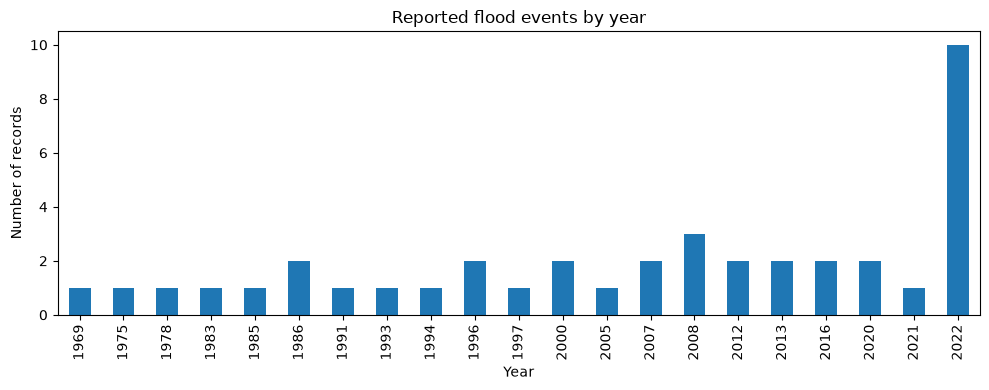

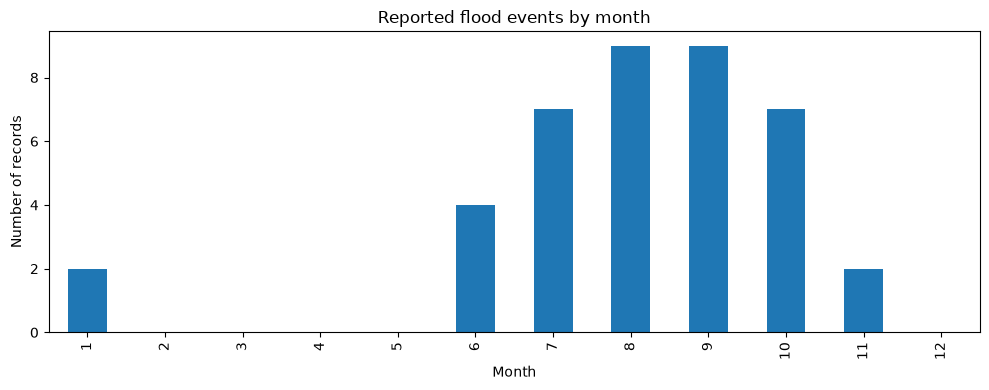

,event_records
event_year,
1969,1
1975,1
1978,1
1983,1
1985,1
1986,2
1991,1
1993,1
1994,1


,event_records
event_month,
1,2
6,4
7,7
8,9
9,9
10,7
11,2


In [70]:
year_counts = df["event_year"].value_counts().sort_index()
month_counts = df["event_month"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
year_counts.plot(kind="bar")
plt.title("Reported flood events by year")
plt.xlabel("Year"); plt.ylabel("Number of records"); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
month_counts.reindex(range(1, 13), fill_value=0).plot(kind="bar")
plt.title("Reported flood events by month")
plt.xlabel("Month"); plt.ylabel("Number of records"); plt.tight_layout(); plt.show()

display(year_counts.rename("event_records").to_frame())
display(month_counts.rename("event_records").to_frame())

## 10. Download daily weather from NASA POWER

This section requests daily point data for a representative Hyderabad coordinate. It automatically saves the returned data as `data/processed/flood/hyderabad_nasa_power_daily.csv`.

The date range is based on the event inventory, with a 7-day buffer around it. NASA POWER availability can vary by parameter and date. If the API is temporarily unavailable or the runtime has no internet access, the cell reports the error; rerun it when connectivity is available.

In [71]:

# NASA POWER daily weather download

NASA_LAT = 17.3850
NASA_LON = 78.4867

valid_dates = df["event_start_date"].dropna()

if valid_dates.empty:
    raise ValueError("No valid event dates found.")

# NASA POWER daily meteorological data starts in 1981
NASA_AVAILABLE_FROM = pd.Timestamp("1981-01-01")

api_start_date = max(
    valid_dates.min() - pd.Timedelta(days=7),
    NASA_AVAILABLE_FROM
)

latest_event_end = (
    df["event_end_date"].dropna().max()
    if df["event_end_date"].notna().any()
    else valid_dates.max()
)

api_end_date = latest_event_end + pd.Timedelta(days=7)

api_start = api_start_date.strftime("%Y%m%d")
api_end = api_end_date.strftime("%Y%m%d")

parameters = "PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M"

url = "https://power.larc.nasa.gov/api/temporal/daily/point"

params = {
    "parameters": parameters,
    "community": "AG",
    "longitude": NASA_LON,
    "latitude": NASA_LAT,
    "start": api_start,
    "end": api_end,
    "format": "JSON"
}

print("Requesting NASA POWER:", api_start, "to", api_end)

response = requests.get(url, params=params, timeout=120)

if response.status_code != 200:
    print("HTTP status:", response.status_code)
    print("NASA POWER response:", response.text[:2000])
    response.raise_for_status()

payload = response.json()

parameter_data = payload.get("properties", {}).get("parameter", {})

if not parameter_data:
    raise ValueError("NASA POWER returned no weather parameters.")

weather = pd.DataFrame(parameter_data)
weather.index.name = "date_yyyymmdd"
weather = weather.reset_index()

weather["date"] = pd.to_datetime(
    weather["date_yyyymmdd"],
    format="%Y%m%d",
    errors="coerce"
)

weather = weather.rename(columns={
    "PRECTOTCORR": "precipitation_mm_day",
    "T2M": "temperature_2m_c",
    "T2M_MAX": "temperature_2m_max_c",
    "T2M_MIN": "temperature_2m_min_c",
    "RH2M": "relative_humidity_2m_percent"
})

weather = weather.drop(columns=["date_yyyymmdd"], errors="ignore")
weather = weather.sort_values("date").reset_index(drop=True)

weather.to_csv(WEATHER_FILE, index=False)

print("Weather records downloaded:", len(weather))
print("Weather file saved:", WEATHER_FILE)
display(weather.head())
display(weather.describe())


Requesting NASA POWER: 19810101 to 20221207
Weather records downloaded: 15316
Weather file saved: c:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\hyderabad_nasa_power_daily.csv


,precipitation_mm_day,temperature_2m_c,temperature_2m_max_c,temperature_2m_min_c,relative_humidity_2m_percent,date
0,0.03,21.94,30.19,15.03,51.32,1981-01-01
1,0.00,21.55,30.48,14.06,44.06,1981-01-02
2,0.06,22.30,31.09,15.44,58.57,1981-01-03
3,0.00,22.46,31.24,15.36,56.43,1981-01-04
4,0.00,23.23,32.44,15.14,51.50,1981-01-05


,precipitation_mm_day,temperature_2m_c,temperature_2m_max_c,temperature_2m_min_c,relative_humidity_2m_percent,date
count,15316.000000,15316.00000,15316.000000,15316.000000,15316.000000,15316
mean,2.291486,25.99951,32.415751,20.547240,60.698150,2001-12-19 12:00:00
min,0.000000,15.59000,20.740000,8.090000,5.030000,1981-01-01 00:00:00
25%,0.000000,23.21000,28.780000,17.427500,42.915000,1991-06-26 18:00:00
50%,0.020000,25.31000,30.910000,21.490000,65.085000,2001-12-19 12:00:00
75%,1.232500,28.54000,35.850000,23.030000,79.020000,2012-06-13 06:00:00
max,136.230000,38.09000,45.530000,32.230000,95.470000,2022-12-07 00:00:00
std,6.612540,4.22466,4.795217,4.129206,20.893519,NaN


## 11. Match weather to event dates

For each event, calculate event-day weather and the total/mean precipitation and mean temperature over the seven days before the event. This is regional context, not a causal flood model.

In [72]:
weather_features = weather.copy()
weather_features = weather_features.set_index("date").sort_index()

event_weather_rows = []
for idx, row in df.iterrows():
    event_date = row["event_start_date"]
    if pd.isna(event_date):
        continue
    event_date = pd.Timestamp(event_date).normalize()
    pre = weather_features.loc[
        (weather_features.index >= event_date - pd.Timedelta(days=7)) &
        (weather_features.index < event_date)
    ]
    same = weather_features.loc[weather_features.index == event_date]

    rec = {
        "source_row_index": idx,
        "event_start_date": event_date,
        "pre7d_precipitation_sum_mm": pre["precipitation_mm_day"].replace(-999, np.nan).sum(min_count=1)
            if "precipitation_mm_day" in pre else np.nan,
        "pre7d_precipitation_mean_mm": pre["precipitation_mm_day"].replace(-999, np.nan).mean()
            if "precipitation_mm_day" in pre else np.nan,
        "pre7d_temperature_mean_c": pre["temperature_2m_c"].replace(-999, np.nan).mean()
            if "temperature_2m_c" in pre else np.nan,
        "event_day_precipitation_mm": same["precipitation_mm_day"].replace(-999, np.nan).mean()
            if "precipitation_mm_day" in same else np.nan,
        "event_day_temperature_c": same["temperature_2m_c"].replace(-999, np.nan).mean()
            if "temperature_2m_c" in same else np.nan,
        "event_day_humidity_percent": same["relative_humidity_2m_percent"].replace(-999, np.nan).mean()
            if "relative_humidity_2m_percent" in same else np.nan
    }
    event_weather_rows.append(rec)

event_weather = pd.DataFrame(event_weather_rows)
df = df.merge(event_weather, left_index=True, right_on="source_row_index", how="left")
display(event_weather.head())
print("Events with event-day rainfall match:", event_weather["event_day_precipitation_mm"].notna().sum(), "/", len(event_weather))

,source_row_index,event_start_date,pre7d_precipitation_sum_mm,pre7d_precipitation_mean_mm,pre7d_temperature_mean_c,event_day_precipitation_mm,event_day_temperature_c,event_day_humidity_percent
0,0,1969-09-15,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1975-08-01,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1978-08-01,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1983-09-23,48.84,6.977143,24.221429,6.59,23.96,90.34
4,4,1985-10-05,47.89,6.841429,24.805714,20.05,23.97,89.31


Events with event-day rainfall match: 37 / 40


## 12. Weather analysis around reported events

,count,mean,std,min,25%,50%,75%,max
pre7d_precipitation_sum_mm,37.0,50.893514,49.460439,0.00,15.210000,33.250000,62.420000,202.710000
pre7d_precipitation_mean_mm,37.0,7.270502,7.065777,0.00,2.172857,4.750000,8.917143,28.958571
pre7d_temperature_mean_c,37.0,25.154595,1.889375,19.98,24.520000,25.214286,25.615714,30.394286
event_day_precipitation_mm,37.0,16.488108,20.503579,0.00,2.630000,12.020000,22.920000,104.590000
event_day_temperature_c,37.0,24.487297,1.899821,18.54,24.140000,24.570000,25.080000,28.400000
event_day_humidity_percent,37.0,83.806486,7.277605,64.91,81.470000,85.470000,88.590000,91.030000


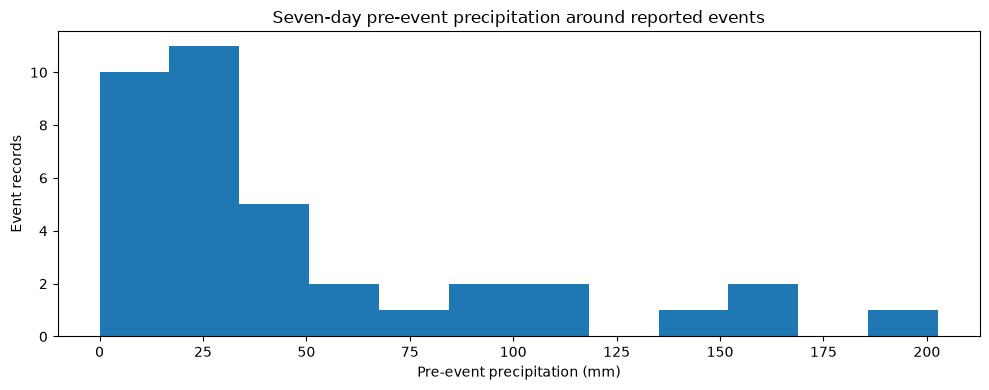

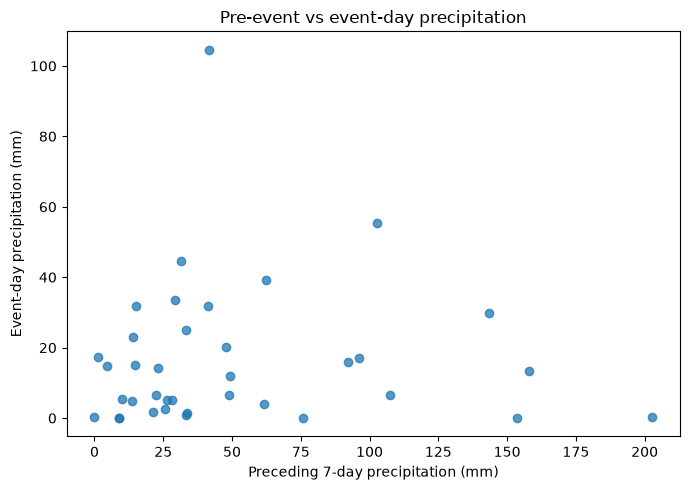

In [73]:
weather_cols = [
    "pre7d_precipitation_sum_mm", "pre7d_precipitation_mean_mm",
    "pre7d_temperature_mean_c", "event_day_precipitation_mm",
    "event_day_temperature_c", "event_day_humidity_percent"
]
display(event_weather[weather_cols].describe().T)

plt.figure(figsize=(10, 4))
event_weather["pre7d_precipitation_sum_mm"].dropna().plot(kind="hist", bins=12)
plt.title("Seven-day pre-event precipitation around reported events")
plt.xlabel("Pre-event precipitation (mm)"); plt.ylabel("Event records")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(
    event_weather["pre7d_precipitation_sum_mm"],
    event_weather["event_day_precipitation_mm"],
    alpha=0.75
)
plt.title("Pre-event vs event-day precipitation")
plt.xlabel("Preceding 7-day precipitation (mm)")
plt.ylabel("Event-day precipitation (mm)")
plt.tight_layout(); plt.show()

## 13. Prepare analysis-ready cleaned outputs

The cleaned file retains original columns and adds transparent derived fields. Missing impact values remain missing; they are not replaced with zero. Duration mismatches remain flagged.

In [74]:
clean_file = OUTPUT_DIR / "clean_historical_flood_events.csv"
event_weather_file = OUTPUT_DIR / "historical_events_with_nasa_power_weather.csv"
df.to_csv(clean_file, index=False)
event_weather.to_csv(event_weather_file, index=False)

print("Saved cleaned event dataset:", clean_file)
print("Saved event-weather features:", event_weather_file)
print("Rows saved:", len(df))

Saved cleaned event dataset: c:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\historical_flood_experiments\clean_historical_flood_events.csv
Saved event-weather features: c:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\historical_flood_experiments\historical_events_with_nasa_power_weather.csv
Rows saved: 40


## 14. K-Means clustering: compare calendar representations

Clustering is exploratory and does not identify verified flood-risk classes. We compare ordinary month encoding against cyclical month encoding (`sin` and `cos`), which correctly places December close to January.

In [75]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_base = df[["event_year", "event_month", "reported_duration_days"]].copy()
cluster_base = cluster_base.replace([np.inf, -np.inf], np.nan).dropna()

def evaluate_kmeans(features, label):
    scaler = StandardScaler()
    X = scaler.fit_transform(features)
    rows = []
    for k in range(2, min(7, len(features) - 1) + 1):
        labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit_predict(X)
        if len(np.unique(labels)) > 1:
            rows.append({"representation": label, "k": k,
                         "silhouette": silhouette_score(X, labels)})
    return rows

cluster_results = []
if len(cluster_base) >= 5:
    ordinary = cluster_base[["event_year", "event_month", "reported_duration_days"]]
    cyc = cluster_base[["event_year", "reported_duration_days"]].copy()
    cyc["month_sin"] = np.sin(2 * np.pi * cluster_base["event_month"] / 12)
    cyc["month_cos"] = np.cos(2 * np.pi * cluster_base["event_month"] / 12)
    cluster_results += evaluate_kmeans(ordinary, "ordinary_month")
    cluster_results += evaluate_kmeans(cyc, "cyclical_month")
    cluster_results = pd.DataFrame(cluster_results)
    display(cluster_results.sort_values("silhouette", ascending=False))
else:
    print("Not enough complete records for K-Means with these features.")

,representation,k,silhouette
1,ordinary_month,3,0.470692
0,ordinary_month,2,0.446057
2,ordinary_month,4,0.419495
5,ordinary_month,7,0.410596
11,cyclical_month,7,0.400747
3,ordinary_month,5,0.399591
4,ordinary_month,6,0.379080
8,cyclical_month,4,0.367126
9,cyclical_month,5,0.364005
10,cyclical_month,6,0.333456


## 15. Exploratory duration regression (not flood prediction)

This experiment predicts the **reported duration of a recorded event**, not whether a flood will occur. Because there are only about 40 records and duration values may be inconsistent, treat scores as exploratory. Rows with flagged duration mismatches are excluded from this particular experiment; source values are not changed.

In [76]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

feature_cols = [
    "event_year", "event_month",
    "pre7d_precipitation_sum_mm", "event_day_precipitation_mm",
    "event_day_temperature_c", "event_day_humidity_percent"
]
reg_data = df.copy()
reg_data["duration_target"] = reg_data["reported_duration_days"]
if "duration_mismatch" in reg_data:
    reg_data = reg_data.loc[~reg_data["duration_mismatch"]]
reg_data = reg_data.dropna(subset=["duration_target"])
available_features = [c for c in feature_cols if c in reg_data.columns]
X = reg_data[available_features].replace([np.inf, -np.inf], np.nan)
y = reg_data["duration_target"]

print("Usable records:", len(reg_data))
print("Features:", available_features)

if len(reg_data) >= 10 and len(available_features) >= 2:
    models = {
        "Linear Regression": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                       ("scale", StandardScaler()), ("model", LinearRegression())]),
        "Polynomial Regression (degree 2)": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                       ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                                       ("scale", StandardScaler()), ("model", Ridge(alpha=1.0))]),
        "Ridge": Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler()), ("model", Ridge(alpha=1.0))]),
        "Lasso": Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler()), ("model", Lasso(alpha=0.1, max_iter=10000))]),
        "Decision Tree": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                   ("model", DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE))]),
        "Random Forest": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                   ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                                   random_state=RANDOM_STATE))]),
        "Extra Trees": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                 ("model", ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2,
                                                               random_state=RANDOM_STATE))]),
        "Gradient Boosting": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                       ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))]),
        "SVR": Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler()), ("model", SVR())]),
        "KNN Regressor": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                   ("scale", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=3))])
    }
    cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = []
    for name, model in models.items():
        result = cross_validate(model, X, y, cv=cv,
                                scoring={"mae": "neg_mean_absolute_error",
                                         "rmse": "neg_root_mean_squared_error",
                                         "r2": "r2"})
        scores.append({
            "algorithm": name,
            "CV_MAE": -result["test_mae"].mean(),
            "CV_RMSE": -result["test_rmse"].mean(),
            "CV_R2": result["test_r2"].mean()
        })
    duration_results = pd.DataFrame(scores).sort_values("CV_MAE")
    display(duration_results)
    duration_results.to_csv(OUTPUT_DIR / "duration_regression_comparison.csv", index=False)
else:
    print("Skipped regression: too few valid rows or usable features. Do not force a model on insufficient data.")

Usable records: 39
Features: ['event_year', 'event_month', 'pre7d_precipitation_sum_mm', 'event_day_precipitation_mm', 'event_day_temperature_c', 'event_day_humidity_percent']


,algorithm,CV_MAE,CV_RMSE,CV_R2
8,SVR,6.066068,10.194354,-0.135549
6,Extra Trees,7.497224,10.297443,-3.195631
5,Random Forest,7.735428,10.390000,-2.557892
9,KNN Regressor,7.855952,10.625106,-3.056572
7,Gradient Boosting,8.653267,12.269670,-7.142510
4,Decision Tree,8.973117,12.923566,-6.059490
2,Ridge,9.859857,13.166100,-3.343449
3,Lasso,9.871687,13.240845,-3.363544
0,Linear Regression,10.189055,13.854872,-3.731932
1,Polynomial Regression (degree 2),11.185966,15.456610,-11.756586


### How to interpret duration regression

- Lower MAE and RMSE are better; R² may be negative on a small/noisy dataset.
- Cross-validation scores are exploratory, not independent final test scores.
- Algorithm ranking is unstable with a small dataset.
- Do not deploy this as a flood-occurrence or flood-risk predictor.

## 16. Why a flood/no-flood classifier is not trained

In [80]:
df["event_start_date"] = pd.to_datetime(
    df["Start_Date_Parsed"], errors="coerce"
)
df["event_end_date"] = pd.to_datetime(
    df["End_Date_Parsed"], errors="coerce"
)
print("Historical event rows:", len(df))

# Count records with valid historical flood-event dates
if "event_start_date" in df.columns:
    valid_events = df["event_start_date"].notna().sum()
elif "event_start_date_x" in df.columns:
    valid_events = df["event_start_date_x"].notna().sum()
elif "event_start_date_y" in df.columns:
    valid_events = df["event_start_date_y"].notna().sum()
else:
    valid_events = df["Start_Date_Parsed"].notna().sum()

print("Verified flood-event records:", int(valid_events))
print("Verified non-flood observations: 0 (not supplied in this inventory)")

print("\nConclusion: supervised flood/no-flood classification is not valid with this dataset alone.")


Historical event rows: 40
Verified flood-event records: 40
Verified non-flood observations: 0 (not supplied in this inventory)

Conclusion: supervised flood/no-flood classification is not valid with this dataset alone.


A classifier requires both:
- positive examples: confirmed flood events; and
- negative examples: locations and dates with verified absence of flooding.

Treating every date absent from this event inventory as a non-flood date would create false labels. The earlier classifier approach should therefore not be used as a validated project result.

## 17. Save experiment summary and final audit

In [81]:

# Recreate standard date columns from the original parsed columns
df["event_start_date"] = pd.to_datetime(
    df["Start_Date_Parsed"], errors="coerce"
)
df["event_end_date"] = pd.to_datetime(
    df["End_Date_Parsed"], errors="coerce"
)

summary = {
    "source_file": str(SOURCE_FILE),
    "source_records": int(len(raw)),
    "valid_event_start_dates": int(df["event_start_date"].notna().sum()),
    "duration_mismatches": int(df["duration_mismatch"].sum()),
    "weather_downloaded": bool(WEATHER_FILE.exists()),
    "weather_records": int(len(weather)) if "weather" in globals() else 0,
    "event_weather_matches": (
        int(event_weather["event_day_precipitation_mm"].notna().sum())
        if "event_weather" in globals() else 0
    ),
    "verified_negative_examples": 0,
    "flood_classifier_trained": False,
    "cleaned_dataset": str(clean_file)
}

summary_file = OUTPUT_DIR / "historical_flood_analysis_summary.json"

with open(summary_file, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4, default=str)

print(json.dumps(summary, indent=4))

print("\nAll generated files:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print("-", path.name)


{
    "source_file": "c:\\Users\\sanaf\\OneDrive\\Desktop\\urban-risk-analytics\\data\\processed\\flood\\hyderabad_historical_flood_events.csv",
    "source_records": 40,
    "valid_event_start_dates": 40,
    "duration_mismatches": 1,
    "weather_downloaded": true,
    "weather_records": 15316,
    "event_weather_matches": 37,
    "verified_negative_examples": 0,
    "flood_classifier_trained": false,
    "cleaned_dataset": "c:\\Users\\sanaf\\OneDrive\\Desktop\\urban-risk-analytics\\data\\processed\\flood\\historical_flood_experiments\\clean_historical_flood_events.csv"
}

All generated files:
- clean_historical_flood_events.csv
- duration_regression_comparison.csv
- event_cluster_comparison.csv
- event_counts_by_month.csv
- event_counts_by_year.csv
- event_district_mentions.csv
- event_type_counts.csv
- historical_events_with_exploratory_clusters.csv
- historical_events_with_nasa_power_weather.csv
- historical_flood_analysis_summary.json
- historical_flood_event_audit.csv
- historic

## 18. Project conclusion

This notebook produces a cleaned historical flood-event inventory, event impact summaries, district/cause analysis, NASA POWER regional weather context, exploratory clustering, and (only when data suffices) exploratory duration-regression comparisons.

**Do not claim:** validated flood/no-flood accuracy, plot-level weather, causal relationships, or future flood forecasting from these data alone.

**For future supervised flood prediction:** obtain a labelled dataset containing both flood and verified non-flood observations with matched location, date, and weather features. Keep the present analysis reproducible and transparent.